# Histopathology Slide Exploration & Preprocessing

Hands-on walkthrough of the TCGA-BRCA diagnostic slides (`.svs`, Aperio format) in `Pathology/cohort/cohort.csv` (110 patients, ILC vs IDC), before committing to the full automated `tile_and_extract.py` batch run (see the project plan). Goal: understand what's actually in these files, what MPP means for *this* cohort, and what a model's "tile" input physically represents, by looking at real data rather than assuming.

**Run order matters** — later cells depend on variables set in earlier ones. If a cell errors because `openslide` isn't installed yet, install it first (`brew install openslide && pip install openslide-python`), then restart the kernel and re-run from the top.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

Image.MAX_IMAGE_PIXELS = None  # trusted source (our own downloaded TCGA slides)

try:
    import openslide
    HAS_OPENSLIDE = True
    print(f"openslide {openslide.__library_version__} available")
except ImportError:
    HAS_OPENSLIDE = False
    print("openslide NOT installed yet -- metadata-only cells below will still work (plain PIL),\n"
          "but thumbnail/tissue-detection/tiling cells need it. Install with:\n"
          "  brew install openslide && pip install openslide-python")

SLIDE_DIR = Path("/path/to/slides")
slide_files = sorted(p.name for p in SLIDE_DIR.glob("*.svs") if not p.name.startswith("."))
print(f"{len(slide_files)} slides found")

openslide 4.0.1 available
110 slides found


## 1. What's actually in one slide file?

Aperio `.svs` files are pyramidal TIFFs: one full-resolution image plus several progressively downsampled levels, all in one file, so viewers can zoom without re-reading everything. The scanner also embeds its own metadata (magnification, microns-per-pixel, scan date, instrument ID) as plain text in the TIFF `ImageDescription` tag — readable even without OpenSlide.

In [2]:
sample_file = slide_files[0]
sample_path = SLIDE_DIR / sample_file
print(f"Sample slide: {sample_file}")
print(f"File size on disk: {sample_path.stat().st_size / 1e6:.0f} MB\n")

img = Image.open(sample_path)
print(f"Level 0 (full-res) dimensions: {img.size[0]:,} x {img.size[1]:,} pixels")
print(f"Number of pyramid frames: {img.n_frames}\n")

desc = img.tag_v2.get(270, "")
print("Raw Aperio ImageDescription tag:")
print(desc)

mpp = float(re.search(r"MPP\s*=\s*([\d.]+)", desc).group(1))
mag = re.search(r"AppMag\s*=\s*([\d.]+)", desc).group(1)
print(f"\n--> Native resolution: {mpp} microns/pixel, scanned at {mag}x magnification")

Sample slide: TCGA-A2-A0CO-01Z-00-DX1.B191DADE-7DEA-4575-AED7-1C52BE15B8D5.svs
File size on disk: 727 MB

Level 0 (full-res) dimensions: 110,414 x 63,320 pixels
Number of pyramid frames: 5

Raw Aperio ImageDescription tag:
Aperio Image Library v10.2.20
115000x63420 [0,0 110414x63320] (256x256) JPEG/RGB Q=30|AppMag = 40|StripeWidth = 1000|ScanScope ID = SS1248CNTLR|Filename = TCGA-A2-A0CO-01Z-00-DX1|Title = TCGA-A2-A0CO-01Z-00-DX1|Date = 03/01/11|Time = 12:04:23|User = d3930408-9557-437d-aac9-5116284e0884|Parmset = GOG136 on RESBPCLACIE01|MPP = 0.2505|Left = 24.461119|Top = 18.808918|LineCameraSkew = 0.001550|LineAreaXOffset = 0.000000|LineAreaYOffset = 0.000000|Focus Offset = 0.000000|DSR ID = resc3-dsr2|ImageID = 54276|Exposure Time = 109|Exposure Scale = 0.000001|DisplayColor = 0|OriginalWidth = 115000|OriginalHeight = 63420|ICC Profile = ScanScope v1

--> Native resolution: 0.2505 microns/pixel, scanned at 40x magnification


In [3]:
# The pyramid: level 0 is full-res; the small "level 1" is a separate embedded
# thumbnail (not part of the downsample chain); levels 2+ are progressively
# downsampled versions of the same image.
level0_width = img.size[0]
for i in range(img.n_frames):
    img.seek(i)
    downsample = level0_width / img.size[0]
    print(f"  level {i}: {img.size[0]:>7,} x {img.size[1]:>7,} px  (downsample {downsample:.1f}x)")
img.seek(0)  # reset to level 0

  level 0: 110,414 x  63,320 px  (downsample 1.0x)
  level 1:   1,024 x     587 px  (downsample 107.8x)
  level 2:  27,603 x  15,830 px  (downsample 4.0x)
  level 3:   6,900 x   3,957 px  (downsample 16.0x)
  level 4:   3,450 x   1,978 px  (downsample 32.0x)


## 2. Full-cohort audit: is MPP/magnification consistent across all 110 slides?

Already checked once this session (read-only, no OpenSlide needed) — repeating here with a plot so you can see the spread yourself, not just trust a summary statistic.

Readable via plain PIL: 95/110
Failed (need OpenSlide -- likely JPEG2000 compression): 15
  TCGA-A8-A0AB-01Z-00-DX1.103ED338-A0F9-403B-A10C-49840BD60EB8.svs: UnidentifiedImageError
  TCGA-AC-A23E-01Z-00-DX1.F12A5A87-72CF-42F8-A6EC-8E7FAD80B1F7.svs: UnidentifiedImageError
  TCGA-AC-A23G-01Z-00-DX1.2F0326F7-6B77-4B3F-B4FA-59ADB785AA07.svs: UnidentifiedImageError
  TCGA-AC-A23H-01Z-00-DX1.8E0AE339-1047-4CA5-BFC5-37A3B10FD8B5.svs: UnidentifiedImageError
  TCGA-AC-A2BK-01Z-00-DX1.A3A1F275-9CDC-48BA-BB81-BCA6F02ACA94.svs: UnidentifiedImageError
  TCGA-AC-A2BM-01Z-00-DX1.162A9FA9-6E61-48BF-B0A5-C6C7640ABD9B.svs: UnidentifiedImageError
  TCGA-AC-A2FK-01Z-00-DX1.033F3C27-9860-4EF3-9330-37DE5EC45724.svs: UnidentifiedImageError
  TCGA-AC-A3BB-01Z-00-DX1.CE889249-2A5E-44DA-B04E-746BE82CD805.svs: UnidentifiedImageError
  TCGA-AC-A6IW-01Z-00-DX1.C4514189-E64F-4603-8970-230FA2BB77FC.svs: UnidentifiedImageError
  TCGA-AC-A6NO-01Z-00-DX1.61B7F48C-6D6E-4C1B-B236-DD130ECBDA9D.svs: UnidentifiedImageError


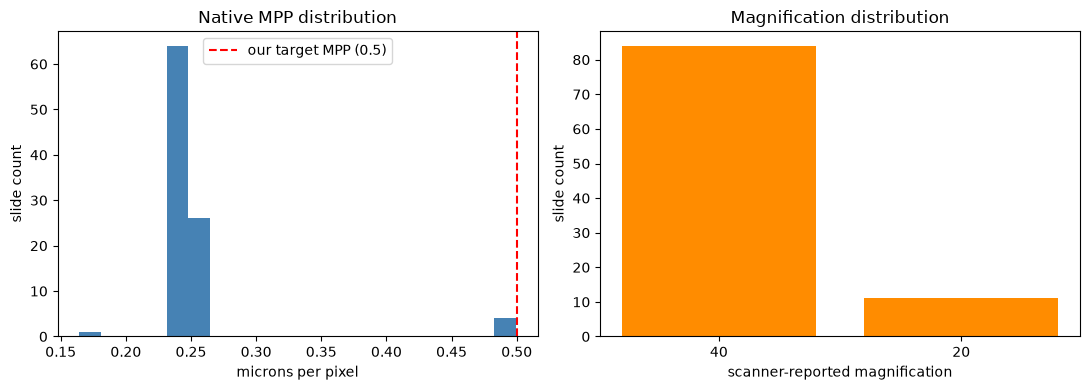


MPP range: 0.1644 - 0.4992, mean 0.2566
This is WHY every slide gets resampled to one common target MPP before tiling --
at native resolution, the same pixel count means different physical tissue area
on different slides, so tiles wouldn't be comparable across the cohort.


In [4]:
mpps, mags, failed = [], [], []
for fname in slide_files:
    try:
        im = Image.open(SLIDE_DIR / fname)
        d = im.tag_v2.get(270, "")
        m = re.search(r"MPP\s*=\s*([\d.]+)", d)
        a = re.search(r"AppMag\s*=\s*([\d.]+)", d)
        if m:
            mpps.append(float(m.group(1)))
        if a:
            mags.append(a.group(1))
    except Exception as e:
        failed.append((fname, type(e).__name__))

print(f"Readable via plain PIL: {len(slide_files) - len(failed)}/{len(slide_files)}")
print(f"Failed (need OpenSlide -- likely JPEG2000 compression): {len(failed)}")
for fname, err in failed:
    print(f"  {fname}: {err}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(mpps, bins=20, color="steelblue")
axes[0].axvline(0.5, color="red", linestyle="--", label="our target MPP (0.5)")
axes[0].set_xlabel("microns per pixel")
axes[0].set_ylabel("slide count")
axes[0].set_title("Native MPP distribution")
axes[0].legend()

from collections import Counter
mag_counts = Counter(mags)
axes[1].bar(mag_counts.keys(), mag_counts.values(), color="darkorange")
axes[1].set_xlabel("scanner-reported magnification")
axes[1].set_ylabel("slide count")
axes[1].set_title("Magnification distribution")
plt.tight_layout()
plt.show()

print(f"\nMPP range: {min(mpps):.4f} - {max(mpps):.4f}, mean {np.mean(mpps):.4f}")
print("This is WHY every slide gets resampled to one common target MPP before tiling --")
print("at native resolution, the same pixel count means different physical tissue area")
print("on different slides, so tiles wouldn't be comparable across the cohort.")

## 3. What does a 224x224 tile physically represent?

`physical_size_microns = tile_pixels * target_MPP`. At our target of 0.5 MPP (matching H-optimus/Virchow's documented convention -- UNI2-h's own repo doesn't state one, see the project notes), a 224px tile covers 112 x 112 microns -- roughly a few dozen cells across (a typical cell is ~10-20 microns). At native 40x (0.25 MPP) *without* resampling, the same 224px would only cover 56 x 56 microns -- a tighter field of view, and not comparable to a slide scanned at 20x.

In [5]:
TARGET_MPP = 0.5
TILE_PX = 224

for label, this_mpp in [("target (0.5 MPP, 20x-equivalent)", TARGET_MPP),
                        ("native 40x", 0.25), ("native 20x", 0.5)]:
    physical_um = TILE_PX * this_mpp
    print(f"{label:35s}: {TILE_PX}px -> {physical_um:.0f} x {physical_um:.0f} microns "
          f"({physical_um/1000:.3f} x {physical_um/1000:.3f} mm)")

target (0.5 MPP, 20x-equivalent)   : 224px -> 112 x 112 microns (0.112 x 0.112 mm)
native 40x                         : 224px -> 56 x 56 microns (0.056 x 0.056 mm)
native 20x                         : 224px -> 112 x 112 microns (0.112 x 0.112 mm)


## 4. See the actual tissue: thumbnail

Requires OpenSlide for `get_thumbnail` (handles all compression formats, including the 15 slides plain PIL can't read).

Level count: 4
Level dimensions: ((110414, 63320), (27603, 15830), (6900, 3957), (3450, 1978))
Level downsamples: (1.0, 4.000036227946238, 16.002025359571917, 32.00809571958207)
OpenSlide-reported MPP: x=0.2505, y=0.2505


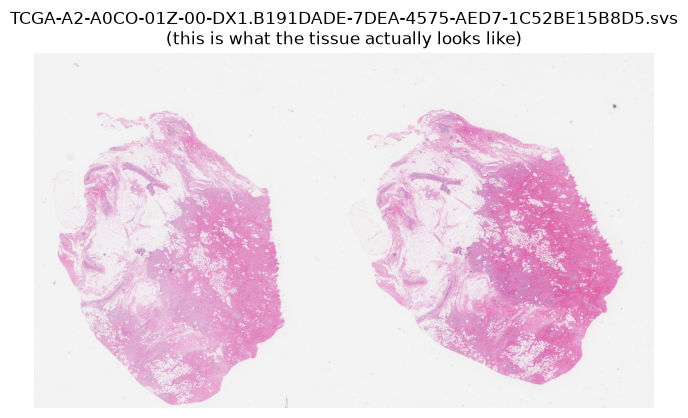

In [6]:
if not HAS_OPENSLIDE:
    print("Skipping -- install openslide first (see cell 1).")
else:
    slide = openslide.OpenSlide(str(sample_path))
    print(f"Level count: {slide.level_count}")
    print(f"Level dimensions: {slide.level_dimensions}")
    print(f"Level downsamples: {slide.level_downsamples}")
    print(f"OpenSlide-reported MPP: x={slide.properties.get('openslide.mpp-x')}, "
          f"y={slide.properties.get('openslide.mpp-y')}")

    thumbnail = slide.get_thumbnail((1024, 1024))
    plt.figure(figsize=(8, 8))
    plt.imshow(thumbnail)
    plt.title(f"{sample_file}\n(this is what the tissue actually looks like)")
    plt.axis("off")
    plt.show()

## 5. Tissue detection (Otsu threshold)

Most of a slide is empty glass/background, not tissue -- extracting tiles everywhere would waste most of the compute budget on blank patches. Standard approach: grayscale the thumbnail, find the threshold that best separates two populations of pixel intensity (Otsu's method, implemented here directly with numpy -- no extra dependency), keep the darker side as "tissue".

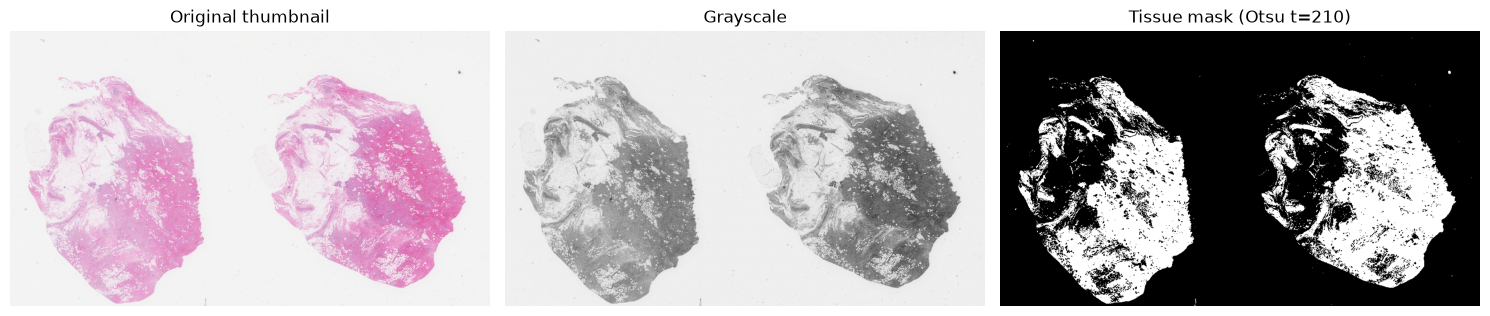

Tissue fraction of thumbnail: 26.2%


In [7]:
def otsu_threshold(gray: np.ndarray) -> int:
    """Classic Otsu's method: find the threshold minimizing within-class variance,
    equivalently maximizing between-class variance. gray: uint8 2D array."""
    hist, _ = np.histogram(gray, bins=256, range=(0, 256))
    hist = hist.astype(float)
    total = hist.sum()
    sum_all = np.dot(np.arange(256), hist)
    sum_bg, weight_bg, best_thresh, best_var = 0.0, 0.0, 0, 0.0
    for t in range(256):
        weight_bg += hist[t]
        if weight_bg == 0:
            continue
        weight_fg = total - weight_bg
        if weight_fg == 0:
            break
        sum_bg += t * hist[t]
        mean_bg = sum_bg / weight_bg
        mean_fg = (sum_all - sum_bg) / weight_fg
        between_var = weight_bg * weight_fg * (mean_bg - mean_fg) ** 2
        if between_var > best_var:
            best_var = between_var
            best_thresh = t
    return best_thresh


if HAS_OPENSLIDE:
    gray = np.array(thumbnail.convert("L"))
    thresh = otsu_threshold(gray)
    tissue_mask = gray < thresh  # tissue is darker (stained) than background glass

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(thumbnail); axes[0].set_title("Original thumbnail"); axes[0].axis("off")
    axes[1].imshow(gray, cmap="gray"); axes[1].set_title("Grayscale"); axes[1].axis("off")
    axes[2].imshow(tissue_mask, cmap="gray"); axes[2].set_title(f"Tissue mask (Otsu t={thresh})"); axes[2].axis("off")
    plt.tight_layout()
    plt.show()
    print(f"Tissue fraction of thumbnail: {tissue_mask.mean():.1%}")
else:
    print("Skipping -- needs the thumbnail from cell 4 (needs openslide).")

## 6. Generate a tile grid over tissue, at the target MPP

Scale the tissue mask (computed on the thumbnail) back up to level-0 pixel coordinates, lay a non-overlapping grid of `TILE_PX x TILE_PX` boxes (in target-MPP-equivalent level-0 pixels) over it, keep only boxes with enough tissue coverage.

Native MPP: 0.2505 -> each 224px output tile spans 447px at level 0
10226 candidate tile positions above 50% tissue, keeping top 1000 (cap=1000)


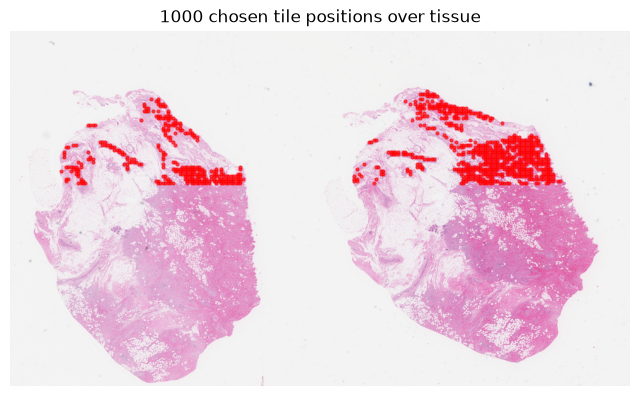

In [8]:
if HAS_OPENSLIDE:
    native_mpp = float(slide.properties.get("openslide.mpp-x", mpp))
    level0_w, level0_h = slide.level_dimensions[0]

    # How many level-0 pixels does one output tile span, given we want each
    # output pixel to represent TARGET_MPP microns?
    level0_px_per_tile = int(round(TILE_PX * TARGET_MPP / native_mpp))
    print(f"Native MPP: {native_mpp:.4f} -> each {TILE_PX}px output tile spans "
          f"{level0_px_per_tile}px at level 0")

    thumb_w, thumb_h = thumbnail.size
    scale_x, scale_y = level0_w / thumb_w, level0_h / thumb_h

    MIN_TISSUE_FRACTION = 0.5
    MAX_TILES = 1000

    candidates = []  # (x0, y0, tissue_fraction) in level-0 coordinates
    thumb_tile_w = max(1, int(level0_px_per_tile / scale_x))
    thumb_tile_h = max(1, int(level0_px_per_tile / scale_y))
    for ty in range(0, thumb_h - thumb_tile_h, max(1, thumb_tile_h)):
        for tx in range(0, thumb_w - thumb_tile_w, max(1, thumb_tile_w)):
            patch = tissue_mask[ty:ty + thumb_tile_h, tx:tx + thumb_tile_w]
            frac = patch.mean() if patch.size else 0.0
            if frac >= MIN_TISSUE_FRACTION:
                x0 = int(tx * scale_x)
                y0 = int(ty * scale_y)
                candidates.append((x0, y0, frac))

    candidates.sort(key=lambda c: -c[2])  # highest tissue fraction first
    chosen = candidates[:MAX_TILES]
    print(f"{len(candidates)} candidate tile positions above {MIN_TISSUE_FRACTION:.0%} tissue, "
          f"keeping top {len(chosen)} (cap={MAX_TILES})")

    # Visualize chosen tile centers on the thumbnail
    plt.figure(figsize=(8, 8))
    plt.imshow(thumbnail)
    xs = [c[0] / scale_x for c in chosen]
    ys = [c[1] / scale_y for c in chosen]
    plt.scatter(xs, ys, s=4, c="red", alpha=0.6)
    plt.title(f"{len(chosen)} chosen tile positions over tissue")
    plt.axis("off")
    plt.show()
else:
    print("Skipping -- needs tissue_mask from cell 5 (needs openslide).")

## 7. Extract and look at actual tiles

Read a handful of the chosen positions at full level-0 resolution, downsample to the output `TILE_PX x TILE_PX`, and display them -- this is exactly what the model sees as one "tile" input.

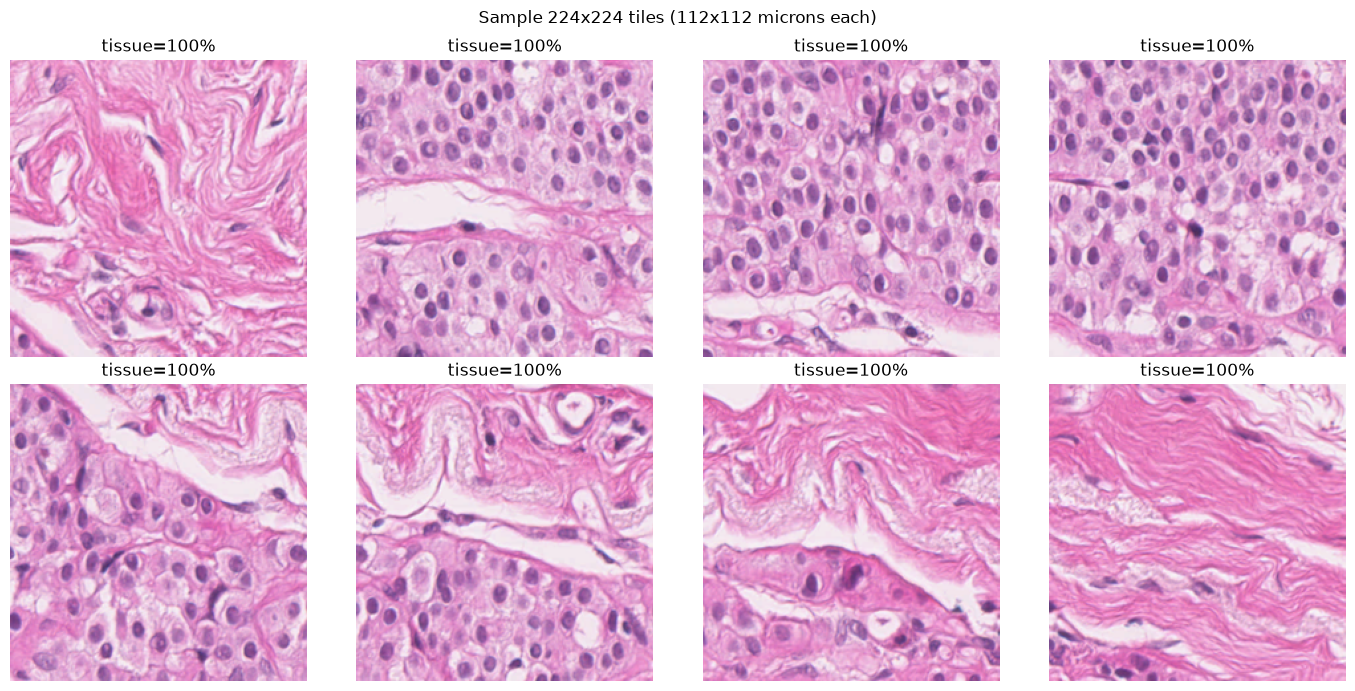

In [9]:
if HAS_OPENSLIDE:
    sample_tiles = []
    for x0, y0, frac in chosen[:8]:
        region = slide.read_region((x0, y0), 0, (level0_px_per_tile, level0_px_per_tile)).convert("RGB")
        tile = region.resize((TILE_PX, TILE_PX), Image.LANCZOS)
        sample_tiles.append((tile, frac))

    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax, (tile, frac) in zip(axes.flat, sample_tiles):
        ax.imshow(tile)
        ax.set_title(f"tissue={frac:.0%}")
        ax.axis("off")
    plt.suptitle(f"Sample {TILE_PX}x{TILE_PX} tiles ({TILE_PX*TARGET_MPP:.0f}x{TILE_PX*TARGET_MPP:.0f} microns each)")
    plt.tight_layout()
    plt.show()
else:
    print("Skipping -- needs openslide.")

## 8. Frozen UNI2-h features on these sample tiles

Reuses the exact model-loading code from `Pathology/code/smoke_test.py` (already proven on this machine: MPS, ~5.6 tiles/sec, loads cleanly). Confirms the tiles produced above are valid model input before committing to the full 110-slide batch run.

In [10]:
import sys
sys.path.insert(0, str(Path("../code").resolve()))
import torch
from smoke_test import load_model

if HAS_OPENSLIDE:
    device = "mps" if torch.backends.mps.is_available() else "cpu"
    model, transform = load_model(device)
    print(f"Model loaded on {device}")

    batch = torch.stack([transform(tile) for tile, _ in sample_tiles]).to(device)
    with torch.inference_mode():
        features = model(batch)
    print(f"Feature shape: {features.shape}  (expect [n_tiles, 1536])")
    print(f"Feature stats: mean={features.mean().item():.4f}, std={features.std().item():.4f}")
else:
    print("Skipping -- needs sample_tiles from cell 7 (needs openslide).")

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model loaded on mps
Feature shape: torch.Size([8, 1536])  (expect [n_tiles, 1536])
Feature stats: mean=0.0050, std=0.4415


## Next steps

Once this notebook's choices look right by eye (tissue mask covers real tissue, tiles look like sensible histology patches, not background or artifacts), the same logic gets turned into the production `tile_and_extract.py` script that streams through all 110 slides x 2 models (baseline CNN + UNI2-h) without saving individual tile images to disk -- see the project plan for the full pipeline.